# Modelling Preparation + Naive Historical Baseline

This notebook prepares the existing **Manhattan + Queens** modelling dataset for Review 1 and builds the first baseline.

### What this notebook does
1. Loads `data/processed/features.csv`.
2. Performs an **80/20 chronological train/test split** using a single time cutoff across all taxi zones.
3. Builds the **168-hour historical baseline** (`trip_count_lag_168h`).
4. Evaluates the baseline using **MAE, RMSE and R²**.
5. Saves the train/test datasets and baseline results under `data/modeling/`.

**No regression models are trained here.** The outputs from this notebook will be used by Model 1, Model 2 and Model 3 notebooks.


## 1. Imports and configuration


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
TRAIN_RATIO = 0.80
            
print('Libraries imported successfully.')


/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Libraries imported successfully.


## 2. Locate the repository and load the processed feature dataset

The path finder below works whether this notebook is opened from the repository root or from the `scripts/` directory.


In [ ]:
def find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    for path in candidates:
        feature_file = path / 'data' / 'processed' / 'features.csv'
        if feature_file.exists():
            return path
    raise FileNotFoundError(
        'Could not find data/processed/features.csv. '
        'Open the notebook inside the project repository or update the path manually.'
    )

REPO_ROOT = find_repo_root()
FEATURES_PATH = REPO_ROOT / 'data' / 'processed' / 'features.csv'
MODELING_DIR = REPO_ROOT / 'models' / 'modeling'
MODELING_DIR.mkdir(parents=True, exist_ok=True)

print('Repository:', REPO_ROOT)
print('Features file:', FEATURES_PATH)
print('Modeling output directory:', MODELING_DIR)


Repository: /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting
Features file: /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting/data/processed/features.csv
Modeling output directory: /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting/data/modeling


In [3]:
df = pd.read_csv(FEATURES_PATH)

required_columns = [
    'PULocationID', 'pickup_hour', 'trip_count',
    'apparent_temperature', 'rain', 'snowfall',
    'precipitation_probability', 'hour', 'day_of_week',
    'month', 'is_weekend', 'is_holiday',
    'trip_count_lag_1h', 'trip_count_lag_24h',
    'trip_count_lag_168h', 'trip_count_roll_3h',
    'trip_count_roll_24h'
]

missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f'Missing required columns: {missing_columns}')

df['pickup_hour'] = pd.to_datetime(df['pickup_hour'])
df = df.sort_values(['pickup_hour', 'PULocationID']).reset_index(drop=True)

print(f'Rows: {len(df):,}')
print(f'Columns: {df.shape[1]}')
print(f'Zones: {df["PULocationID"].nunique()}')
print(f'Unique hourly timestamps: {df["pickup_hour"].nunique():,}')
print(f'Date range: {df["pickup_hour"].min()} to {df["pickup_hour"].max()}')
            
display(df.head())


Rows: 576,288
Columns: 17
Zones: 138
Unique hourly timestamps: 4,176
Date range: 2025-09-08 00:00:00 to 2026-02-28 23:00:00


,PULocationID,pickup_hour,trip_count,apparent_temperature,rain,snowfall,precipitation_probability,hour,day_of_week,month,is_weekend,is_holiday,trip_count_lag_1h,trip_count_lag_24h,trip_count_lag_168h,trip_count_roll_3h,trip_count_roll_24h
0,2,2025-09-08,0,13.8,0.0,0.0,0,0,0,9,False,False,0,0,0,0.000000,0.000000
1,4,2025-09-08,2,15.7,0.0,0.0,0,0,0,9,False,False,11,96,27,13.000000,33.333332
2,7,2025-09-08,11,15.2,0.0,0.0,0,0,0,9,False,False,18,26,30,14.000000,14.333333
3,8,2025-09-08,0,15.5,0.0,0.0,0,0,0,9,False,False,0,0,1,0.000000,0.125000
4,9,2025-09-08,0,15.0,0.0,0.0,0,0,0,9,False,False,1,0,0,0.666667,0.250000


## 3. Validate the modelling table

Because this is zone-hour data, every timestamp should contain the same set of zones in the current processed dataset. We also check for duplicate zone-hour rows.


In [4]:
duplicate_rows = df.duplicated(['PULocationID', 'pickup_hour']).sum()
rows_per_timestamp = df.groupby('pickup_hour')['PULocationID'].nunique()

print('Duplicate zone-hour rows:', duplicate_rows)
print('Zones per timestamp - min:', rows_per_timestamp.min())
print('Zones per timestamp - max:', rows_per_timestamp.max())

assert duplicate_rows == 0, 'Duplicate PULocationID + pickup_hour rows found.'
assert rows_per_timestamp.nunique() == 1, 'The number of zones changes across timestamps.'

print('Validation passed.')


Duplicate zone-hour rows: 0
Zones per timestamp - min: 138
Zones per timestamp - max: 138
Validation passed.


## 4. Chronological 80/20 train/test split

The split is done on **unique timestamps**, not individual rows. This guarantees that all zones at a given hour belong to the same side of the split and prevents temporal leakage between train and test.


In [5]:
unique_times = np.sort(df['pickup_hour'].unique())
split_index = int(len(unique_times) * TRAIN_RATIO)

train_end_time = pd.Timestamp(unique_times[split_index - 1])
test_start_time = pd.Timestamp(unique_times[split_index])

train_df = df[df['pickup_hour'] <= train_end_time].copy()
test_df = df[df['pickup_hour'] >= test_start_time].copy()

print(f'Train period: {train_df["pickup_hour"].min()} -> {train_df["pickup_hour"].max()}')
print(f'Test period : {test_df["pickup_hour"].min()} -> {test_df["pickup_hour"].max()}')
print(f'Train rows  : {len(train_df):,}')
print(f'Test rows   : {len(test_df):,}')
print(f'Train timestamps: {train_df["pickup_hour"].nunique():,}')
print(f'Test timestamps : {test_df["pickup_hour"].nunique():,}')

assert train_df['pickup_hour'].max() < test_df['pickup_hour'].min()

split_summary = pd.DataFrame({
    'dataset': ['train', 'test'],
    'start': [train_df['pickup_hour'].min(), test_df['pickup_hour'].min()],
    'end': [train_df['pickup_hour'].max(), test_df['pickup_hour'].max()],
    'rows': [len(train_df), len(test_df)],
    'timestamps': [train_df['pickup_hour'].nunique(), test_df['pickup_hour'].nunique()]
})
display(split_summary)


Train period: 2025-09-08 00:00:00 -> 2026-01-25 03:00:00
Test period : 2026-01-25 04:00:00 -> 2026-02-28 23:00:00
Train rows  : 460,920
Test rows   : 115,368
Train timestamps: 3,340
Test timestamps : 836


,dataset,start,end,rows,timestamps
0,train,2025-09-08 00:00:00,2026-01-25 03:00:00,460920,3340
1,test,2026-01-25 04:00:00,2026-02-28 23:00:00,115368,836


In [6]:
train_path = MODELING_DIR / 'train.csv'
test_path = MODELING_DIR / 'test.csv'
split_path = MODELING_DIR / 'split_summary.csv'

train_df.to_csv(train_path, index=False)
test_df.to_csv(test_path, index=False)
split_summary.to_csv(split_path, index=False)

print('Saved:')
print(' -', train_path)
print(' -', test_path)
print(' -', split_path)


Saved:
 - /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting/data/modeling/train.csv
 - /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting/data/modeling/test.csv
 - /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting/data/modeling/split_summary.csv


## 5. Naive historical baseline: same hour one week earlier

The baseline prediction is simply:

`prediction = trip_count_lag_168h`

This asks: **If the same zone had X trips at this hour last week, can we use X as this hour's prediction?**

The baseline is evaluated only on the chronological test set.


In [7]:
baseline_test = test_df[[
    'PULocationID', 'pickup_hour', 'trip_count', 'trip_count_lag_168h'
]].copy()

baseline_test = baseline_test.rename(columns={
    'trip_count': 'actual_demand',
    'trip_count_lag_168h': 'baseline_prediction'
})

missing_baseline = baseline_test['baseline_prediction'].isna().sum()
if missing_baseline:
    raise ValueError(f'Baseline contains {missing_baseline} missing predictions.')

y_true = baseline_test['actual_demand']
y_pred = baseline_test['baseline_prediction']

baseline_mae = mean_absolute_error(y_true, y_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_true, y_pred))
baseline_r2 = r2_score(y_true, y_pred)

baseline_metrics = pd.DataFrame({
    'model': ['Naive 168-hour historical baseline'],
    'MAE': [baseline_mae],
    'RMSE': [baseline_rmse],
    'R2': [baseline_r2],
    'test_rows': [len(baseline_test)]
})

display(baseline_metrics)


,model,MAE,RMSE,R2,test_rows
0,Naive 168-hour historical baseline,9.30739,24.056583,0.877566,115368


## 6. Inspect baseline predictions

The table below shows a few zone-hour predictions from the test period.


In [8]:
baseline_test['error'] = baseline_test['actual_demand'] - baseline_test['baseline_prediction']
baseline_test['absolute_error'] = baseline_test['error'].abs()

display(baseline_test.head(20))

baseline_predictions_path = MODELING_DIR / 'baseline_168h_predictions.csv'
baseline_metrics_path = MODELING_DIR / 'baseline_metrics.csv'

baseline_test.to_csv(baseline_predictions_path, index=False)
baseline_metrics.to_csv(baseline_metrics_path, index=False)

print('Saved:')
print(' -', baseline_predictions_path)
print(' -', baseline_metrics_path)


,PULocationID,pickup_hour,actual_demand,baseline_prediction,error,absolute_error
460920,2,2026-01-25 04:00:00,0,0,0,0
460921,4,2026-01-25 04:00:00,14,36,-22,22
460922,7,2026-01-25 04:00:00,0,20,-20,20
460923,8,2026-01-25 04:00:00,0,0,0,0
460924,9,2026-01-25 04:00:00,0,0,0,0
460925,10,2026-01-25 04:00:00,0,0,0,0
460926,12,2026-01-25 04:00:00,0,0,0,0
460927,13,2026-01-25 04:00:00,1,1,0,0
460928,15,2026-01-25 04:00:00,0,0,0,0
460929,16,2026-01-25 04:00:00,0,0,0,0


Saved:
 - /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting/data/modeling/baseline_168h_predictions.csv
 - /Users/sadhanatp/Desktop/Amrita /Semester VII/23CSE452/Case Study/Group/nyc-taxi-demand-forecasting/data/modeling/baseline_metrics.csv


## 7. Quick visual check of the baseline

This aggregates the zone-level test data to total Manhattan + Queens hourly demand. It is only a sanity check; the official metrics above are calculated at the zone-hour level.


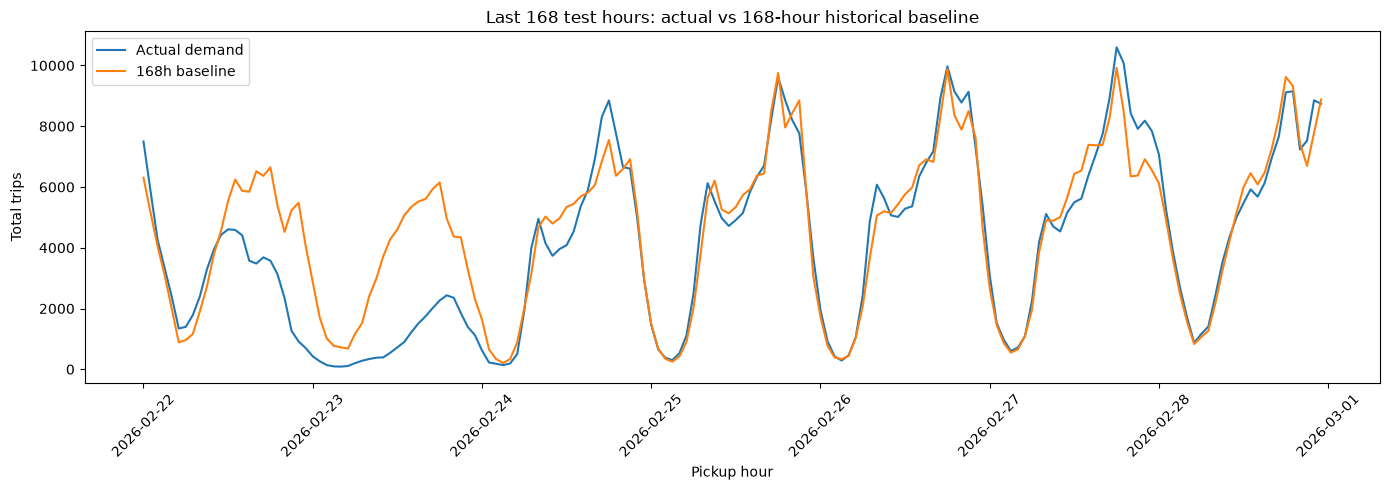

In [9]:
hourly_check = (
    baseline_test
    .groupby('pickup_hour', as_index=False)
    .agg(
        actual_demand=('actual_demand', 'sum'),
        baseline_prediction=('baseline_prediction', 'sum')
    )
    .tail(168)
)

plt.figure(figsize=(14, 5))
plt.plot(hourly_check['pickup_hour'], hourly_check['actual_demand'], label='Actual demand')
plt.plot(hourly_check['pickup_hour'], hourly_check['baseline_prediction'], label='168h baseline')
plt.xlabel('Pickup hour')
plt.ylabel('Total trips')
plt.title('Last 168 test hours: actual vs 168-hour historical baseline')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


## 8. Preparation complete

The next notebooks should load:

- `data/modeling/train.csv`
- `data/modeling/test.csv`
- `data/modeling/baseline_metrics.csv`

Next steps are **Model 1 → Model 2 → Model 3 → model comparison → weather with-vs-without experiment**.

**Do not randomly shuffle the train/test data. Keep the same chronological split for every model so the comparison is fair.**
